In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Fathur Rasyid Irimawa 202431036

In [2]:
dataseed = pd.read_csv("Crop_recommendation.csv")
print(dataseed.head())
dataseed.info()
print(dataseed.describe())

#Fathur Rasyid Irimawa 202431036

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB
              

In [4]:
print(dataseed['label'].value_counts())
# Penjelasan: setiap kelas ada 100 baris, kelas seimbang.

#Fathur Rasyid Irimawa 202431036

pomegranate    100
grapes         100
chickpea       100
mango          100
muskmelon      100
watermelon     100
pigeonpeas     100
maize          100
coconut        100
banana         100
cotton         100
blackgram      100
apple          100
papaya         100
orange         100
coffee         100
rice           100
mothbeans      100
lentil         100
mungbean       100
jute           100
kidneybeans    100
Name: label, dtype: int64


In [5]:
print("Nilai kosong:")
print(dataseed.isna().sum())
print("Jumlah duplikat:", dataseed.duplicated().sum())
df = dataseed.copy()

#Fathur Rasyid Irimawa 202431036

Nilai kosong:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Jumlah duplikat: 0


In [6]:
x = df.drop('label', axis=1)
y = df['label']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0, stratify=y)

print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

#Fathur Rasyid Irimawa 202431036

Data latih: (1650, 7) | Data uji: (550, 7)


In [16]:
rentang = pd.DataFrame({'min': x_train.min(), 'max': x_train.max()})
rentang['rentang'] = rentang['max'] - rentang['min']
print(rentang.sort_values('rentang', ascending=False))
# Rainfall memiliki rentang nilai paling lebar (sekitar 20–299, selisih ~280), diikuti K, N, dan P. 
# Ph di angka 3,5–9,9 (selisih ~6). 
# Karena KNN bergantung pada jarak Euclidean, data tanpa scaling akan membuat perhitungan jarak ditentukan oleh rainfall, sementara ph dan temperature nyaris tidak dianggap. 
# Fitur wajib distandarisasi lebih dulu sebelum masuk model.

#Fathur Rasyid Irimawa 202431036

                   min         max     rentang
rainfall     20.211267  298.560117  278.348850
K             5.000000  205.000000  200.000000
N             0.000000  140.000000  140.000000
P             5.000000  145.000000  140.000000
humidity     14.258040   99.981876   85.723836
temperature   8.825675   43.675493   34.849818
ph            3.504752    9.935091    6.430338


In [8]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

#Fathur Rasyid Irimawa 202431036

In [17]:
params = {'knn__n_neighbors': range(1, 20)}

grid_search = GridSearchCV(
    estimator = pipeline,
    param_grid = params,
    scoring = 'accuracy',
    cv = 5,
    n_jobs = 1
)
grid_search.fit(x_train, y_train)

print("k terbaik           :", grid_search.best_params_['knn__n_neighbors'])
print("Skor validasi silang:", grid_search.best_score_)
# Parameter terbaik ada pada k = 1 dengan skor CV ~0,972.
# Nilai k = 1 ada di batas bawah grid dan umumnya rentan noise, tapi karena dataset ini bersih dan batas antar kelasnya jelas, 1 tetangga terdekat sudah cukup akurat.

#Fathur Rasyid Irimawa 202431036

k terbaik           : 1
Skor validasi silang: 0.9721212121212123


In [11]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)

#Fathur Rasyid Irimawa 202431036

In [18]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
# Akurasi test tembus ~0,984 (541/550 benar), beda tipis dengan skor CV (0,972) menandakan model cukup konsisten dan aman dari overfitting.
# Kasus spesifik: kelas rice (padi). Error paling sering muncul saat model membedakan rice dan jute.
# Precision rice (~0,92) -> dari semua tebakan "rice", 92% akurat; 2 sampel sisanya adalah jute.
# Recall rice (~0,88) -> dari total data aktual rice, 88% ditebak benar; 3 dari 25 sampel meleset ke jute.
# Wajar tertukar, karena syarat tumbuh jute dan rice sama-sama butuh curah hujan dan kelembapan tinggi.

#Fathur Rasyid Irimawa 202431036

Accuracy: 0.9836363636363636

Classification Report:
               precision    recall  f1-score   support

       apple       1.00      1.00      1.00        25
      banana       1.00      1.00      1.00        25
   blackgram       1.00      0.96      0.98        25
    chickpea       1.00      1.00      1.00        25
     coconut       1.00      1.00      1.00        25
      coffee       0.96      1.00      0.98        25
      cotton       1.00      1.00      1.00        25
      grapes       1.00      1.00      1.00        25
        jute       0.88      0.88      0.88        25
 kidneybeans       1.00      1.00      1.00        25
      lentil       0.96      0.96      0.96        25
       maize       1.00      1.00      1.00        25
       mango       1.00      1.00      1.00        25
   mothbeans       0.96      1.00      0.98        25
    mungbean       1.00      1.00      1.00        25
   muskmelon       1.00      1.00      1.00        25
      orange       1.00    

In [19]:
data_baru = pd.DataFrame([[90, 42, 43, 20.9, 82.0, 6.5, 202.9]], columns=x.columns)

dalam_rentang = (data_baru.iloc[0] >= x_train.min()) & (data_baru.iloc[0] <= x_train.max())
print("Fitur dalam rentang data latih:", dalam_rentang.all())
print("Prediksi:", best_model.predict(data_baru))
# Titik input ini valid karena semua fiturnya (N, P, K, temperature, humidity, ph, rainfall) masih masuk dalam rentang min-max data latih, jadi model aman dari ekstrapolasi. 
# Prediksi di luar batas latih akan tidak akurat karena KNN tidak punya referensi tetangga di area tersebut.
# Output prediksi: rice - cocok dengan karakteristik padi yang butuh N, curah hujan, dan kelembapan tinggi.

#Fathur Rasyid Irimawa 202431036

Fitur dalam rentang data latih: True
Prediksi: ['rice']


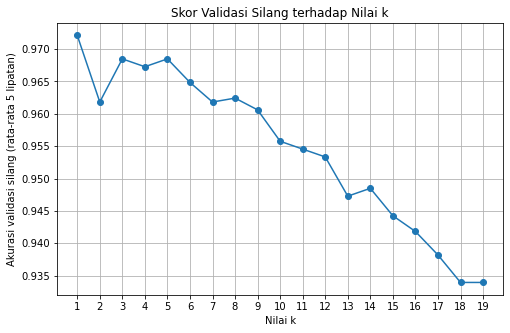

In [15]:
hasil = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(8, 5))
plt.plot(hasil['param_knn__n_neighbors'], hasil['mean_test_score'], marker='o')
plt.xticks(range(1, 20))
plt.xlabel("Nilai k")
plt.ylabel("Akurasi validasi silang (rata-rata 5 lipatan)")
plt.title("Skor Validasi Silang terhadap Nilai k")
plt.grid(True)
plt.show()

#Fathur Rasyid Irimawa 202431036